# Project 11  Incident grounded AI accountability scenarios

**Authors:** Siddhant Mathapati and Weican Ye  
**Target:** *Futures*  
**Source:** AI Incident Database Excel export dated 19 October 2026. https://incidentdatabase.ai/research/snapshots/

This is an executable research workflow, not a completed account of institutional redress. Incident records contain roles and risk classifications, but no verified response or remedy variable. The four displayed outputs are reproducible exploratory results. Table 2 is an **evidence screening result**; a publication claim about redress requires the human coding template exported below to be completed and checked. The 2026 records are a retrospective stress test, not a forecast of 2030.

The selected anchor article is Alon et al. (2025), *The future of artificial intelligence: Insights from recent Delphi studies*, *Futures* 165, 103514, https://doi.org/10.1016/j.futures.2024.103514. The proposed distinct contribution is a traceable incident to scenario workflow. Check nearby work, including https://doi.org/10.1016/j.futures.2026.103879, before claiming novelty.


## Planned methodology

1. Load the pinned public workbook, retain its version, and audit keys, nulls and report URL repetition.
2. Define 2024–2025 incidents as the construction period and 2026 incidents as a later stress test. The 2026 interval is shorter and subject to reporting delays.
3. Use literal equality of normalized developer and deployer strings as a **recorded role string** indicator. Different strings do not establish separate legal entities or responsibility.
4. Produce Table 1 for RQ1: risk domain by actor string relationship, with harmed party field coverage.
5. Produce Table 2 for RQ2: source availability and narrow response word screening by actor string relationship. Export a stratified coding template; independently review public incident pages and source evidence before testing an actual redress association.
6. Produce Figure 3 for RQ3: complete case estimates and conservative bounds arising from unclassified risk domains.
7. Produce Figure 4 for RQ4: three observable signposts in 2024, 2025 and 2026. Compare the later period with earlier evidence without claiming future predictive validity.
8. Save the tables as CSV, figures as PDF and PNG, and all results in one ZIP. Before submission, two coders must adjudicate response and remedy labels and repeat the analysis with reporting-depth sensitivity checks.


### Step 1  Set paths and find the public workbook
The input search supports a Kaggle upload under `/kaggle/input` and a local copy next to the notebook. The versioned filename prevents silently using a newer export.

In [1]:
# Step 1 / input provenance: locate the pinned AIID export and create output directory.
from pathlib import Path
import re, json, zipfile, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import fisher_exact
from IPython.display import display

NAME = 'AIID_Excel_Export-20261019.xlsx'
candidates = list(Path('/kaggle/input').rglob(NAME)) if Path('/kaggle/input').exists() else []
candidates += [Path.cwd()/NAME, Path.cwd()/'upload'/NAME, Path('/workspace/scratch/7bef03d2111b/upload')/NAME]
source = next((p for p in candidates if p.is_file()), None)
if source is None:
    raise FileNotFoundError(f'Upload {NAME} as a Kaggle dataset, or put it beside this notebook.')
out = (Path('/kaggle/working') if Path('/kaggle/working').exists() else Path.cwd())/'project11_results'
out.mkdir(parents=True, exist_ok=True)
sha256 = hashlib.sha256(source.read_bytes()).hexdigest()
print('Input:', source, 'SHA256:', sha256, 'Results:', out)


Input: /kaggle/input/datasets/siddhant22132/datafor/AIID_Excel_Export-20261019.xlsx SHA256: 41758b56b948f62f75385108977f58af8e1faefad03bb0203cda03b889660ae2 Results: /kaggle/working/project11_results


### Step 2  Load the sheets and audit the units of analysis
The first two rows of `Incidents` and the first row of `Reports` are banners, so the actual headers need explicit positions. IDs, rather than report URLs, define unique incidents.

In [2]:
# Step 2 / EDA: load records, validate IDs, and document missingness and duplication.
inc = pd.read_excel(source, sheet_name='Incidents', header=2)
rep = pd.read_excel(source, sheet_name='Reports', header=1)
ent = pd.read_excel(source, sheet_name='Entities', header=1).dropna(how='all')
assert inc['Incident ID'].notna().all() and inc['Incident ID'].is_unique
assert rep['Report Number'].notna().all() and rep['Report Number'].is_unique
assert not inc.duplicated().any()
url = rep['URL'].dropna().astype(str).str.strip()
url = url[url.ne('')]
audit = pd.DataFrame([
    ('incident rows',len(inc)),('report rows',len(rep)),('entity rows',len(ent)),
    ('duplicate incident IDs',int(inc['Incident ID'].duplicated().sum())),
    ('duplicate incident rows',int(inc.duplicated().sum())),
    ('missing risk domain',int(inc['Risk Domain'].isna().sum())),
    ('missing sector of deployment',int(inc['Sector of Deployment'].isna().sum())),
    ('missing report URL',int(rep['URL'].isna().sum())),
    ('extra repeated URL occurrences',int(url.duplicated().sum()))],columns=['check','count'])
audit.to_csv(out/'data_audit.csv',index=False)
display(audit)


,check,count
0,incident rows,1749
1,report rows,7955
2,entity rows,7507
3,duplicate incident IDs,0
4,duplicate incident rows,0
5,missing risk domain,253
6,missing sector of deployment,1543
7,missing report URL,812
8,extra repeated URL occurrences,63


### Step 3  Define periods and recorded actor relationship
`same recorded string` is conservative literal matching; `different recorded strings` includes generic or multiple actor lists. It is a screening variable requiring manual entity review for substantive accountability claims.

In [3]:
# Step 3 / cohort definition: 2024–2025 construction and 2026 later-period stress test.
inc['date']=pd.to_datetime(inc['date'],errors='coerce')
inc['year']=pd.to_numeric(inc['year'],errors='coerce')
assert (inc.loc[inc['date'].notna(),'date'].dt.year == inc.loc[inc['date'].notna(),'year']).all()
def norm(s): return re.sub(r'\s+',' ',str(s).casefold().strip())
inc['actor_relation']=np.where(inc['developer'].map(norm)==inc['deployer'].map(norm),'same recorded string','different recorded strings')
inc['risk_domain']=inc['Risk Domain'].fillna('Unclassified')
inc['harmed_present']=inc['harmed'].notna() & inc['harmed'].astype(str).str.strip().ne('')
construction=inc[inc['year'].isin([2024,2025])].copy()
later=inc[inc['year'].eq(2026)].copy()
print('Construction incidents:',len(construction),'Later incidents:',len(later))


Construction incidents: 770 Later incidents: 267


### Step 4  Table 1 for RQ1  Recorded role structure and risk domain
This table maps observed combinations and harmed-field availability. It does not code whether responsibility was legally clear.

In [4]:
# Step 4 / RQ1: calculate and export the actor relationship × risk domain table.
t1=(construction.groupby(['risk_domain','actor_relation'],dropna=False)
    .agg(incidents=('Incident ID','size'), harmed_field_present=('harmed_present','sum'), median_reports=('report_count','median'))
    .reset_index())
t1['share_within_actor_group']=(t1['incidents']/t1.groupby('actor_relation')['incidents'].transform('sum')).round(3)
t1=t1.sort_values(['risk_domain','actor_relation'])
t1.to_csv(out/'table1_actor_risk.csv',index=False)
print('TABLE 1 · RQ1 · incident counts, composition and data coverage')
display(t1)


TABLE 1 · RQ1 · incident counts, composition and data coverage


,risk_domain,actor_relation,incidents,harmed_field_present,median_reports,share_within_actor_group
0,"AI system safety, failures, and limitations",different recorded strings,35,35,1.0,0.055
1,"AI system safety, failures, and limitations",same recorded string,34,34,2.0,0.250
2,Discrimination and Toxicity,different recorded strings,30,30,2.0,0.047
3,Discrimination and Toxicity,same recorded string,25,24,2.0,0.184
4,Human-Computer Interaction,different recorded strings,13,13,2.0,0.021
5,Human-Computer Interaction,same recorded string,9,9,3.0,0.066
6,Malicious Actors & Misuse,different recorded strings,372,372,2.0,0.587
7,Malicious Actors & Misuse,same recorded string,20,20,1.5,0.147
8,Misinformation,different recorded strings,89,89,1.0,0.140
9,Misinformation,same recorded string,28,28,1.5,0.206


### Step 5  Table 2 for RQ2  Evidence screening and manual coding sample
A deliberately narrow word pattern finds descriptions that **mention** a possible response. It is neither a verified response nor a remedy label. Report counts do not supply incident to report links in this workbook. Table 2 is a publication figure only after replacing this screening result with independently reviewed coding.

In [5]:
# Step 5 / RQ2: screen text for evidence to review and export a stratified coding template.
pattern=r'\b(?:apolog(?:y|ized|ised)|compensat(?:e|ed|ion)|appeal(?:ed|s)?|refund(?:ed|s)?|settlement|investigat(?:ed|ion)|suspend(?:ed|sion)|recall(?:ed)?|fine(?:d|s)?)\b'
construction['response_word_hit']=construction['description'].fillna('').str.contains(pattern,case=False,regex=True)
t2=(construction.groupby('actor_relation').agg(incidents=('Incident ID','size'),median_reports=('report_count','median'),
        with_three_plus_reports=('report_count',lambda s:int((s>=3).sum())),response_word_hits=('response_word_hit','sum')).reset_index())
t2['word_hit_rate']=(t2['response_word_hits']/t2['incidents']).round(3)
t2.to_csv(out/'table2_evidence_screen.csv',index=False)
print('TABLE 2 · RQ2 · evidence screening only; no verified remedy outcome')
display(t2)
# Draw up to 120 incidents, balanced by year and recorded role group where possible.
parts=[]
for _,g in construction.groupby(['year','actor_relation']):
    parts.append(g.sample(n=min(len(g),30),random_state=11))
sample=pd.concat(parts).sort_values('Incident ID').copy()
template=sample[['Incident ID','year','title','description','developer','deployer','harmed','risk_domain','report_count','actor_relation']].copy()
for c in ['sector_coded','actor_entities_verified','response_documented','redress_route_documented','source_url','coder_1','coder_2','adjudicated_note']:
    template[c]=''
template.to_csv(out/'manual_coding_template.csv',index=False)
print('Coding template exported:',len(template),'incidents; two independent coders should use documented/absent/unclear categories.')


TABLE 2 · RQ2 · evidence screening only; no verified remedy outcome


,actor_relation,incidents,median_reports,with_three_plus_reports,response_word_hits,word_hit_rate
0,different recorded strings,634,2.0,189,64,0.101
1,same recorded string,136,2.0,54,13,0.096


Coding template exported: 120 incidents; two independent coders should use documented/absent/unclear categories.


### Step 6  Figure 3 for RQ3  Classification sensitivity
For each risk domain, the lower bound treats all unclassified incidents as outside the domain; the upper bound assigns all of them to that domain. Bounds are intentionally wide and are not confidence intervals. Complete case shares use only classified incidents.

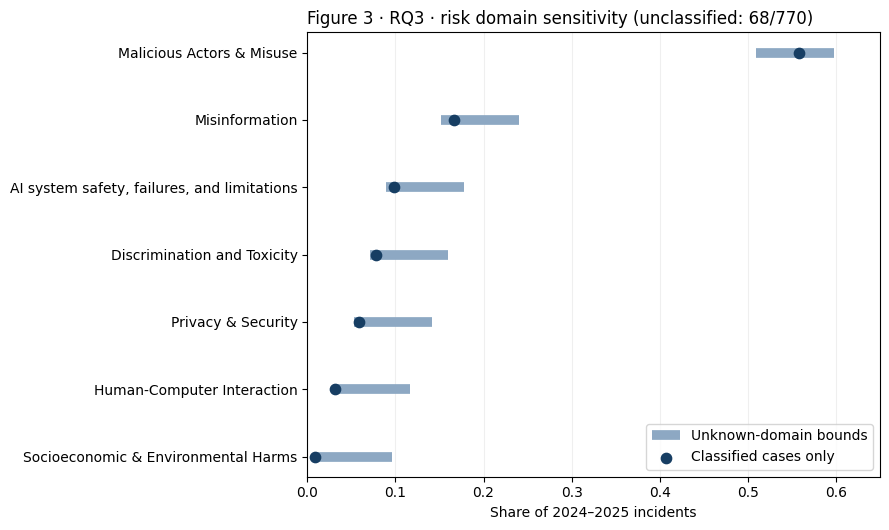

In [6]:
# Step 6 / RQ3: plot complete case shares and extreme missing-classification bounds.
n=len(construction); miss=construction['Risk Domain'].isna().sum(); known=n-miss
counts=construction['Risk Domain'].value_counts().sort_values(ascending=True)
sens=pd.DataFrame({'risk_domain':counts.index,'classified_count':counts.values})
sens['complete_case_share']=sens['classified_count']/known
sens['lower_bound']=sens['classified_count']/n
sens['upper_bound']=(sens['classified_count']+miss)/n
sens.to_csv(out/'figure3_sensitivity_values.csv',index=False)
fig,ax=plt.subplots(figsize=(9,5.4))
y=np.arange(len(sens))
ax.hlines(y,sens.lower_bound,sens.upper_bound,color='#8da8c3',lw=7,label='Unknown-domain bounds')
ax.scatter(sens.complete_case_share,y,color='#173e63',s=55,zorder=3,label='Classified cases only')
ax.set_yticks(y,sens.risk_domain);ax.set_xlabel('Share of 2024–2025 incidents')
ax.set_title(f'Figure 3 · RQ3 · risk domain sensitivity (unclassified: {miss}/{n})',loc='left',fontsize=12)
ax.set_xlim(0,max(.65,sens.upper_bound.max()+.04));ax.grid(axis='x',alpha=.2);ax.legend(loc='lower right')
fig.tight_layout();fig.savefig(out/'figure3_classification_sensitivity.pdf',bbox_inches='tight');fig.savefig(out/'figure3_classification_sensitivity.png',dpi=180,bbox_inches='tight')
plt.show()


### Step 7  Figure 4 for RQ4  Retrospective signposts
These are measurable signals of record structure and coverage. They can guide scenario revision, but they do **not** measure transparency or redress capacity. The partial 2026 period and reporting lags make the comparison descriptive.

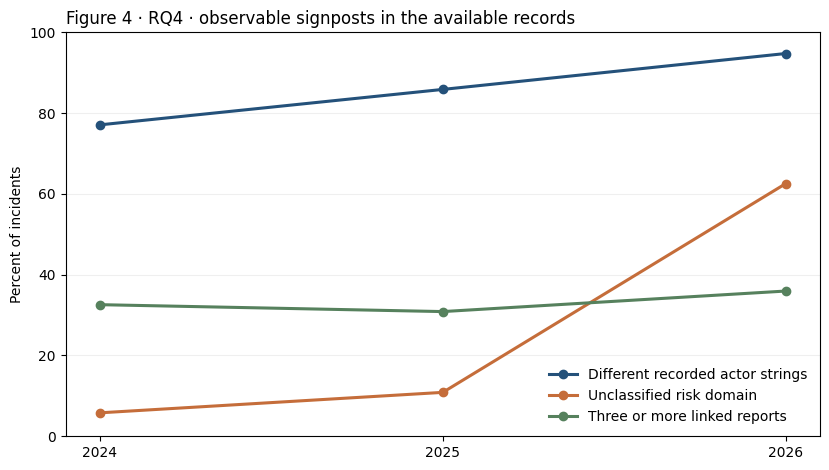

Underlying yearly rates and denominators:


,year,incidents,different_actor_strings,unclassified_domain,three_plus_reports
0,2024,310,0.771,0.058,0.326
1,2025,460,0.859,0.109,0.309
2,2026,267,0.948,0.625,0.360


In [7]:
# Step 7 / RQ4: compare candidate signposts across the observed years.
period=inc[inc['year'].isin([2024,2025,2026])].copy()
signs=period.groupby('year').agg(incidents=('Incident ID','size'),different_actor_strings=('actor_relation',lambda s:s.eq('different recorded strings').mean()),unclassified_domain=('Risk Domain',lambda s:s.isna().mean()),three_plus_reports=('report_count',lambda s:s.ge(3).mean())).reset_index()
signs.to_csv(out/'figure4_signpost_values.csv',index=False)
fig,ax=plt.subplots(figsize=(8.4,4.8))
for col,label,color in [('different_actor_strings','Different recorded actor strings','#24517a'),('unclassified_domain','Unclassified risk domain','#c56d3a'),('three_plus_reports','Three or more linked reports','#56815d')]:
    ax.plot(signs.year.astype(int),100*signs[col],marker='o',lw=2.2,label=label,color=color)
ax.set_xticks([2024,2025,2026]);ax.set_ylim(0,100);ax.set_ylabel('Percent of incidents')
ax.set_title('Figure 4 · RQ4 · observable signposts in the available records',loc='left',fontsize=12)
ax.grid(axis='y',alpha=.2);ax.legend(frameon=False,loc='best');fig.tight_layout()
fig.savefig(out/'figure4_observed_signposts.pdf',bbox_inches='tight');fig.savefig(out/'figure4_observed_signposts.png',dpi=180,bbox_inches='tight')
plt.show()
print('Underlying yearly rates and denominators:');display(signs.round(3))


### Step 8  Validation gate for the final response and redress analysis
After independent coding, load a completed copy of the template as `manual_coding_completed.csv` beside this notebook or in `/kaggle/input`. The cell produces an association table only if every sampled row has adjudicated response and redress codes. Never convert blank or unclear codes into absence.

In [8]:
# Step 8 / RQ2 completion gate: run the adjudicated analysis only with complete human coding.
completed_candidates=list(Path('/kaggle/input').rglob('manual_coding_completed.csv')) if Path('/kaggle/input').exists() else []
completed_candidates += [Path.cwd()/'manual_coding_completed.csv']
completed=next((p for p in completed_candidates if p.exists()),None)
if completed is None:
    print('Human coding pending. Table 2 remains an evidence screening result; no response or redress association is asserted.')
else:
    coded=pd.read_csv(completed)
    required={'Incident ID','actor_relation','response_documented','redress_route_documented','coder_1','coder_2'}
    assert required.issubset(coded.columns) and coded['Incident ID'].is_unique
    assert set(coded['Incident ID'])==set(template['Incident ID'])
    assert coded[['response_documented','redress_route_documented','coder_1','coder_2']].notna().all().all()
    assert set(coded['redress_route_documented'].unique())<= {'documented','explicitly absent','unclear'}
    final=(coded.groupby(['actor_relation','redress_route_documented']).size().rename('incidents').reset_index())
    final.to_csv(out/'table2_adjudicated_redress.csv',index=False)
    display(final)
    valid=coded[coded['redress_route_documented'].ne('unclear')]
    tab=pd.crosstab(valid['actor_relation'],valid['redress_route_documented'].eq('documented'))
    if tab.shape==(2,2): print('Exploratory Fisher exact test, excluding unclear:',fisher_exact(tab))
    else: print('Fisher test skipped because the 2 × 2 table is incomplete.')


Human coding pending. Table 2 remains an evidence screening result; no response or redress association is asserted.


### Step 9  Package the reproducible results
The ZIP includes the four primary outputs, their underlying values, the data audit, a coding template and a provenance note. The original workbook is not repackaged.

In [9]:
# Step 9 / publication export: write provenance and zip every generated figure/table.
provenance={'source_filename':source.name,'sha256':sha256,'construction_years':[2024,2025], 'later_period':2026,
 'counts':{'incidents':len(inc),'reports':len(rep),'entities':len(ent),'construction':len(construction),'later':len(later)},
 'interpretation':'Response word hits are screening flags only; no verified remedy result until manual coding.'}
(out/'provenance.json').write_text(json.dumps(provenance,indent=2))
archive=out.parent/'project11_results.zip'
with zipfile.ZipFile(archive,'w',compression=zipfile.ZIP_DEFLATED) as z:
    for f in sorted(out.iterdir()):
        if f.is_file(): z.write(f,arcname=f.name)
print('ZIP:',archive,'files:',[f.name for f in sorted(out.iterdir())])


ZIP: /kaggle/working/project11_results.zip files: ['data_audit.csv', 'figure3_classification_sensitivity.pdf', 'figure3_classification_sensitivity.png', 'figure3_sensitivity_values.csv', 'figure4_observed_signposts.pdf', 'figure4_observed_signposts.png', 'figure4_signpost_values.csv', 'manual_coding_template.csv', 'provenance.json', 'table1_actor_risk.csv', 'table2_evidence_screen.csv']
